# Artificial Intelligence


* Md. Jalil Piran
* Sejong University
* piran@sejong.ac.kr

# Artificial Neural Networks (ANNS)

<img src="iris.JPG" alt="Iris" width="600"/>

## Iris Flower Classification
- **Goal:** predict an Iris species from four flower measurements using an artificial neural network (ANN).
- **Data:** the default uses the real, bundled scikit-learn Iris dataset (150 flowers, four measurements, three species). No CSV, Google Drive mount, or download is required. Optional CSV loading is included.
- **Environment:** Python 3 with TensorFlow, scikit-learn, pandas, NumPy, Matplotlib, seaborn, joblib, and IPython. Use a Python version supported by your TensorFlow installation.
- **Setup if needed:** run `%pip install tensorflow scikit-learn pandas numpy matplotlib seaborn joblib` in a separate cell, restart the kernel, and then run this notebook from top to bottom. A GPU is unnecessary.
- **Lesson route:** problem → inspect/split data → explore training data → scale → understand/build/train ANN → evaluate → predict → save/reload → optional NumPy backpropagation.
- **Before starting:** know features, targets, train/test splitting, arrays, and basic derivatives. The LR notebook is useful preparation.
- **Learning outcomes:** explain neurons and activations; distinguish loss from accuracy; prevent leakage; interpret learning curves and class metrics; reproduce inference with saved preprocessing.


| Concept |  This ANN lesson |
|---|---|
| Target |  One of three species |
| Output |  Three class probabilities |
| Model |  Layers of weighted sums and nonlinear activations |
| Loss |  Multiclass cross-entropy |
| Prediction |  Class with the highest probability |
| Evaluation |  Accuracy, precision, recall, F1, log loss |

### 1. Import libraries


In [46]:
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
os.environ.setdefault("TF_NUM_INTRAOP_THREADS", "1")
os.environ.setdefault("TF_NUM_INTEROP_THREADS", "1")
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from IPython.display import display
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, f1_score, log_loss,
    classification_report, ConfusionMatrixDisplay, roc_curve, auc)

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.figsize": (8, 4), "figure.dpi": 110})
pd.set_option("display.precision", 4)
print("TensorFlow:", tf.__version__)

TensorFlow: 2.18.0


### 2. Configure the experiment

- Reserve 20% for validation and 20% for testing, leaving 60% for training.

In [47]:
RANDOM_STATE = 42
DATA_PATH = None  # Optional: Path("iris.csv"); None uses the bundled real dataset.
TEST_SIZE = 0.20
VAL_SIZE = 0.20  # Fraction of the complete dataset.
HIDDEN_UNITS = (16, 8)
LEARNING_RATE = 0.01
BATCH_SIZE = 16
MAX_EPOCHS = 300
PATIENCE = 30
ARTIFACT_DIR = Path("ann_iris_artifacts")
feature_columns = ["Sepal_L", "Sepal_W", "Petal_L", "Petal_W"]
class_names = ["Setosa", "Versicolor", "Virginica"]
class_ids = np.arange(len(class_names))
tf.keras.utils.set_random_seed(RANDOM_STATE)

**Hyperparameters:**

- Epochs, batch size, learning rate, and hidden-layer sizes. 


### 3. Load and preview the data

- The default uses `load_iris()`, which is packaged with scikit-learn.
- All four measurements are in centimeters. 
- Sepals are outer flower parts; petals are inner flower parts.
- Optional CSV input accepts the original notebook names (`sepal.length`, …, `variety`) or the short feature names below. 
- Class labels may be species names, `Iris-` names, or integer codes 0–2.

### loads the Iris dataset directly from scikit-learn

In [48]:
if DATA_PATH is None:
    iris = load_iris()
    raw_df = pd.DataFrame(iris.data, columns=feature_columns)
    raw_df["variety"] = np.asarray(class_names)[iris.target]
    print("Source: scikit-learn bundled Iris dataset")
else:
    data_path = Path(DATA_PATH).expanduser()
    if not data_path.is_file():
        raise FileNotFoundError(f"Cannot find {data_path.resolve()}. Set DATA_PATH or use None.")
    raw_df = pd.read_csv(data_path)
    print("Source:", data_path)
print("Rows and columns:", raw_df.shape)
display(raw_df.head())

Source: scikit-learn bundled Iris dataset
Rows and columns: (150, 5)


,Sepal_L,Sepal_W,Petal_L,Petal_W,variety
0,5.1,3.5,1.4,0.2,Setosa
1,4.9,3.0,1.4,0.2,Setosa
2,4.7,3.2,1.3,0.2,Setosa
3,4.6,3.1,1.5,0.2,Setosa
4,5.0,3.6,1.4,0.2,Setosa


- Each row is one flower. The four input columns are measurements; `variety` is the target. Do not include the target among the input features.

### Load the dataset from a local csv file 

In [49]:
from pathlib import Path
import pandas as pd

# Read Iris dataset from the same folder as the code
DATA_PATH = Path("iris.csv")

if not DATA_PATH.is_file():
    raise FileNotFoundError(f"Cannot find {DATA_PATH.resolve()}")

raw_df = pd.read_csv(DATA_PATH)

print("Source:", DATA_PATH.resolve())
print("Rows and columns:", raw_df.shape)
display(raw_df.head())

Source: C:\Users\user\Documents\GitHub\AI\iris.csv
Rows and columns: (149, 5)


,5.1,3.5,1.4,0.2,Iris-setosa
0,4.9,3.0,1.4,0.2,Iris-setosa
1,4.7,3.2,1.3,0.2,Iris-setosa
2,4.6,3.1,1.5,0.2,Iris-setosa
3,5.0,3.6,1.4,0.2,Iris-setosa
4,5.4,3.9,1.7,0.4,Iris-setosa


### Load the Iris dataset directly from an online CSV URL

In [50]:
import pandas as pd

# Load Iris dataset directly from an online CSV
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv"

raw_df = pd.read_csv(url)

print("Source: Online Iris dataset (GitHub)")
print("Rows and columns:", raw_df.shape)
display(raw_df.head())

Source: Online Iris dataset (GitHub)
Rows and columns: (150, 5)


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


### 4. Validate types, missing values, and class labels

- Preserve the original table; normalize column names and convert measurement columns explicitly.
- Stop on missing, infinite, nonpositive, or unrecognized values, rather than silently training on invalid data.
- The bundled dataset is complete. 
- A dataset with missing features needs an imputer fitted on training data only.
- Report exact repeated rows. Equal measurements can occur for different flowers; retain them here because we have no specimen identifiers.
- Real repeated observations should be grouped by specimen before splitting.

In [51]:
df = raw_df.copy()
df.columns = df.columns.str.strip()
df = df.rename(columns={"sepal_length": "Sepal_L", "sepal_width": "Sepal_W",
                        "petal_length": "Petal_L", "petal_width": "Petal_W"})
if df.columns.duplicated().any():
    raise ValueError("Duplicate column names after renaming.")
required = feature_columns + ["species"]
missing = set(required) - set(df.columns)
if missing:
    raise ValueError(f"Missing required columns: {sorted(missing)}")
df = df[required].copy()
for column in feature_columns:
    df[column] = pd.to_numeric(df[column], errors="raise").astype(float)
if not np.isfinite(df[feature_columns].to_numpy()).all() or (df[feature_columns] <= 0).any().any():
    raise ValueError("Measurements must be finite, positive numbers in centimeters.")
label_map = {name.lower(): i for i, name in enumerate(class_names)}
def parse_label(value):
    if pd.isna(value):
        raise ValueError("Missing species label.")
    text = str(value).strip().lower().replace("iris-", "")
    if text in label_map:
        return label_map[text]
    if text in {"0", "1", "2", "0.0", "1.0", "2.0"}:
        return int(float(text))
    raise ValueError(f"Unknown species label: {value!r}")
df["target"] = df["species"].map(parse_label).astype("int32")
df["species"] = np.asarray(class_names)[df["target"]]
if df["target"].value_counts().reindex(class_ids, fill_value=0).min() < 10:
    raise ValueError("Use at least 10 flowers per species for this teaching split.")
df.info()
display(df.isna().sum().to_frame("Missing values"))
print("Repeated measurement/label rows:", df.duplicated(feature_columns + ["target"]).sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Sepal_L  150 non-null    float64
 1   Sepal_W  150 non-null    float64
 2   Petal_L  150 non-null    float64
 3   Petal_W  150 non-null    float64
 4   species  150 non-null    object 
 5   target   150 non-null    int32  
dtypes: float64(4), int32(1), object(1)
memory usage: 6.6+ KB


,Missing values
Sepal_L,0
Sepal_W,0
Petal_L,0
Petal_W,0
species,0
target,0


Repeated measurement/label rows: 1


- Integer species codes are identifiers, not quantities: Virginica is not “twice” Versicolor. 

- An Iris length of zero is invalid; a large but positive measurement should be investigated rather than automatically deleted.

### 5. Split before exploration and scaling

- Use stratification to keep species proportions similar across the three subsets.
- First hold out the test set, then reserve validation data from the remaining rows.
- Split raw measurements; fit the scaler later using only training rows.


In [52]:
X = df[feature_columns].copy()
y = df["target"].copy()
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=VAL_SIZE / (1 - TEST_SIZE),
    stratify=y_dev, random_state=RANDOM_STATE)
train_df = X_train.assign(variety=np.asarray(class_names)[y_train.to_numpy()])
split_counts = pd.DataFrame({name: labels.value_counts().reindex(class_ids, fill_value=0)
    for name, labels in [("Train", y_train), ("Validation", y_val), ("Test", y_test)]})
split_counts.index = class_names
display(split_counts)
display(pd.DataFrame({"Rows": [len(y_train), len(y_val), len(y_test)],
    "Percent": 100 * np.array([len(y_train), len(y_val), len(y_test)]) / len(y)},
    index=["Train", "Validation", "Test"]))
assert set(X_train.index).isdisjoint(X_val.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_val.index).isdisjoint(X_test.index)

,Train,Validation,Test
Setosa,30,10,10
Versicolor,30,10,10
Virginica,30,10,10


,Rows,Percent
Train,90,60.0
Validation,30,20.0
Test,30,20.0


- With the bundled data, expect 90 training, 30 validation, and 30 test flowers, with 30/10/10 examples per species. 

- Thirty test examples give a coarse performance estimate; one error changes accuracy by about 3.3 percentage points.


### 6. Summarize training measurements and class balance

- Use only training observations for summaries that might influence modeling choices.
- Compare the means, standard deviations, quartiles, and class frequencies.


,Sepal_L,Sepal_W,Petal_L,Petal_W
count,90.0000,90.0000,90.0000,90.0000
mean,5.8367,3.0133,3.7511,1.1978
std,0.8661,0.4163,1.7721,0.7613
min,4.3000,2.0000,1.1000,0.1000
25%,5.1000,2.7250,1.6000,0.3000
50%,5.7500,3.0000,4.2500,1.3000
75%,6.4000,3.2000,5.1000,1.8000
max,7.9000,3.9000,6.9000,2.5000


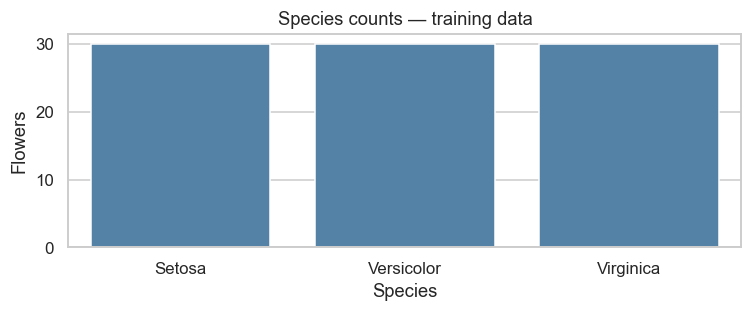

In [53]:
display(X_train.describe())
fig, ax = plt.subplots(figsize=(7, 3))
sns.countplot(data=train_df, x="variety", order=class_names, color="steelblue", ax=ax)
ax.set(title="Species counts — training data", xlabel="Species", ylabel="Flowers")
fig.tight_layout()
plt.show()

- Similar class counts make accuracy useful here. 

- In an imbalanced problem, high accuracy can hide poor performance on a rare class, so inspect per-class recall and macro F1 too.


### 7. Explore how measurements separate species

- Compare sepal and petal measurements in two scatter plots.
- Use species colors without fitting regression lines to class labels.
- These plots show two features at a time; the ANN will use all four features together.


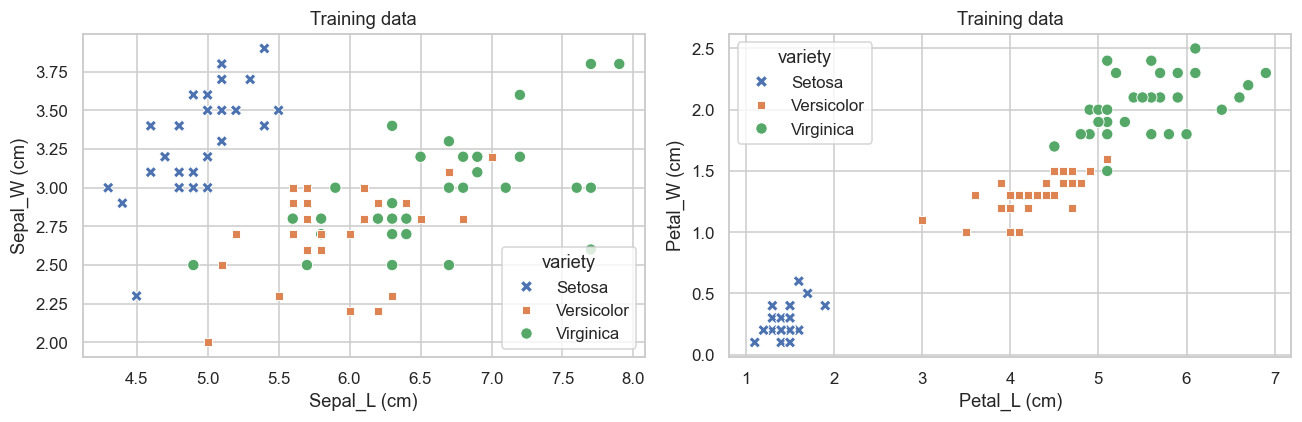

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (horizontal, vertical) in zip(axes, [("Sepal_L", "Sepal_W"), ("Petal_L", "Petal_W")]):
    sns.scatterplot(data=train_df, x=horizontal, y=vertical, hue="variety",
                    style="variety", hue_order=class_names, ax=ax, s=55)
    ax.set(xlabel=f"{horizontal} (cm)", ylabel=f"{vertical} (cm)", title="Training data")
fig.tight_layout()
plt.show()

- Look for a clearly separated class and overlapping classes. 

- Overlap helps explain later errors: similar measurements may lead to similar predicted probabilities.


### 8. Examine numeric correlations

- Pearson correlation measures linear association from −1 to +1.
- Correlate the four numeric measurements, excluding the arbitrary numeric species codes.
- Correlation does not prove causation and is not an automatic reason to delete a feature.


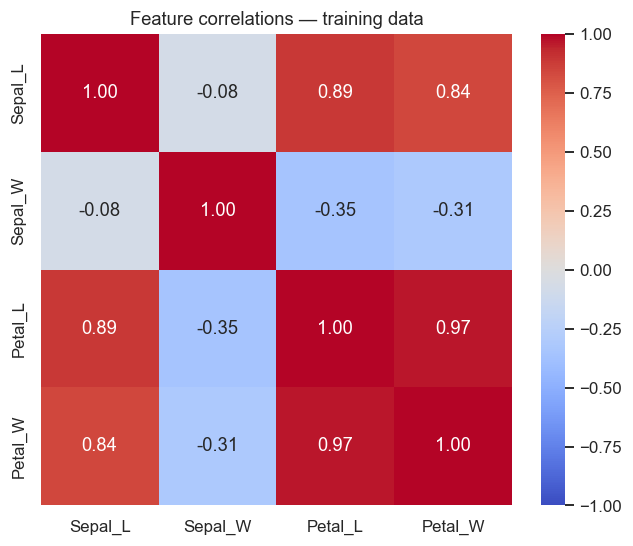

In [55]:
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(X_train.corr(), annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, center=0, square=True, ax=ax)
ax.set_title("Feature correlations — training data")
fig.tight_layout()
plt.show()

- A positive value means the two measurements tend to increase together. 

- A negative value means one tends to decrease as the other increases. 

- A value near zero does not rule out a nonlinear relationship.


### 9. Standardize using training statistics only

- Standardization uses $z=(x-\mu_{train})/\sigma_{train}$ for each feature separately.
- `StandardScaler` centers and scales features; it does **not** constrain them to [0, 1]. 
- Min–max scaling is a different transformation.
- Fit once on training measurements; use the same fitted transformation for validation, testing, and new flowers.
- Scaling helps gradient-based optimization when input features have different spreads.


In [56]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train).astype("float32")
X_val_scaled = scaler.transform(X_val).astype("float32")
X_test_scaled = scaler.transform(X_test).astype("float32")
y_train_array = y_train.to_numpy(dtype="int32")
y_val_array = y_val.to_numpy(dtype="int32")
y_test_array = y_test.to_numpy(dtype="int32")
display(pd.DataFrame({"Training mean (cm)": scaler.mean_,
    "Training standard deviation (cm)": scaler.scale_,
    "Scaled training mean": X_train_scaled.mean(axis=0),
    "Scaled training std": X_train_scaled.std(axis=0)}, index=feature_columns))
print("Input shape:", X_train_scaled.shape, "Target shape:", y_train_array.shape)

,Training mean (cm),Training standard deviation (cm),Scaled training mean,Scaled training std
Sepal_L,5.8367,0.8613,-9.6030e-09,1.0
Sepal_W,3.0133,0.4140,-2.0199e-08,1.0
Petal_L,3.7511,1.7622,-1.0762e-08,1.0
Petal_W,1.1978,0.7570,-1.5563e-08,1.0


Input shape: (90, 4) Target shape: (90,)


- Scaled training means should be close to zero and standard deviations close to one. 
- Validation/test means need not be zero because their statistics were not used in fitting.


## How the ANN works

For one neuron, $z=\sum_j w_jx_j+b$ and $a=\phi(z)$.

- **Weights** control input contributions; a **bias** shifts the weighted sum.
- **Input layer:** receives four standardized measurements; it has no trainable weights itself.
- **Hidden layers:** combine measurements using learned weights and nonlinear activations.
- **ReLU:** $\phi(z)=\max(0,z)$. Nonlinearity allows more flexible decision boundaries.
- Without nonlinear activations, stacked dense layers collapse to an affine transformation.
- **Output layer:** produces three logits, then softmax converts them into nonnegative values summing to one: $p_k=e^{z_k}/\sum_j e^{z_j}$.
- **Cross-entropy:** for the correct class $c$, the loss is $-\log(p_c)$
- A confident wrong answer receives a large penalty.
- **Backpropagation:** uses the chain rule to calculate loss derivatives with respect to weights and biases.
- **Optimizer:** uses these derivatives to update parameters.
- Adam adapts update sizes using running gradient statistics.

Forward pass → compute loss → backpropagate → update parameters. 

Repeat over training batches; validation examples are evaluated without updating parameters.

### 10. Inspect activations and cross-entropy numerically

- Compare ReLU with sigmoid, another activation used later for binary XOR output.
- For a true class of Versicolor, compare a correct confident prediction with a wrong confident prediction.
- Use stable library softmax and clipped logarithms for numerical safety.


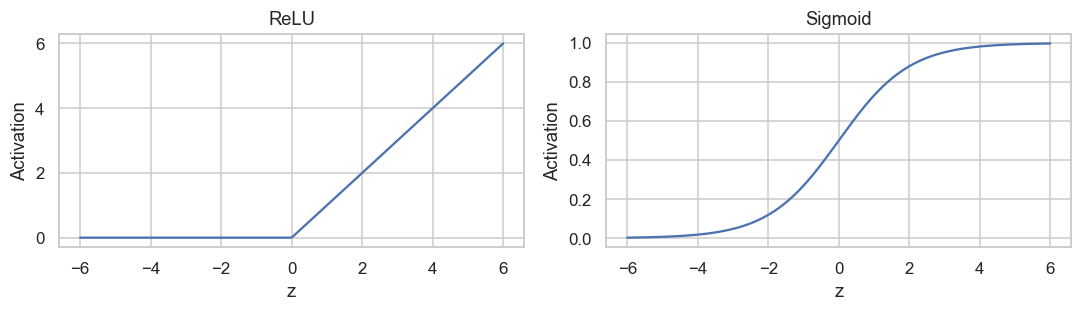

,Scenario,Probability of true class,Cross-entropy
0,Correct and confident,0.90,0.1054
1,Wrong and confident,0.05,2.9957


In [57]:
z = np.linspace(-6, 6, 200)
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].plot(z, np.maximum(0, z)); axes[0].set(title="ReLU", xlabel="z", ylabel="Activation")
axes[1].plot(z, 1 / (1 + np.exp(-z))); axes[1].set(title="Sigmoid", xlabel="z", ylabel="Activation")
fig.tight_layout(); plt.show()
example_probabilities = np.array([[0.05, 0.90, 0.05], [0.90, 0.05, 0.05]])
display(pd.DataFrame({"Scenario": ["Correct and confident", "Wrong and confident"],
    "Probability of true class": example_probabilities[:, 1],
    "Cross-entropy": -np.log(example_probabilities[:, 1])}))

- Cross-entropy rewards probability assigned to the true class. 
- Accuracy only checks which probability is largest; it does not describe the quality of all predicted probabilities.


### 11. Understand integer and one-hot targets

- Keep the main model targets as integer IDs and use `SparseCategoricalCrossentropy`.
- One-hot targets would instead use `CategoricalCrossentropy`. Both encode the same mutually exclusive classes when used correctly.
- Do not use three independent sigmoid outputs for this single-label, three-class problem.


In [58]:
label_examples = y_train_array[:6]
one_hot_examples = tf.keras.utils.to_categorical(label_examples, num_classes=3)
display(pd.DataFrame({"Integer ID": label_examples,
    "Species": np.asarray(class_names)[label_examples],
    "One-hot representation": one_hot_examples.tolist()}))

,Integer ID,Species,One-hot representation
0,2,Virginica,"[0.0, 0.0, 1.0]"
1,0,Setosa,"[1.0, 0.0, 0.0]"
2,1,Versicolor,"[0.0, 1.0, 0.0]"
3,0,Setosa,"[1.0, 0.0, 0.0]"
4,2,Virginica,"[0.0, 0.0, 1.0]"
5,2,Virginica,"[0.0, 0.0, 1.0]"


- An integer target of 1 and a one-hot target of [0, 1, 0] both mean Versicolor. 
- One-hot encoding is demonstrated here, but the training call below uses integer targets consistently.


### 12. Build a compact neural network

- Use architecture **4 → 16 → 8 → 3**, with ReLU hidden layers and a softmax output.
- Start with a small model suited to 90 training flowers.
- Extra layers and neurons do not automatically improve generalization.
- A dense layer with `n_in` inputs and `n_out` outputs has `(n_in + 1) × n_out` parameters, including biases.


In [59]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(RANDOM_STATE)
model = tf.keras.Sequential([
    tf.keras.Input(shape=(len(feature_columns),), name="measurements"),
    tf.keras.layers.Dense(HIDDEN_UNITS[0], activation="relu", name="hidden_1"),
    tf.keras.layers.Dense(HIDDEN_UNITS[1], activation="relu", name="hidden_2"),
    tf.keras.layers.Dense(len(class_names), activation="softmax", name="species")
], name="iris_ann")
model.summary()
layer_widths = [len(feature_columns), *HIDDEN_UNITS, len(class_names)]
expected_parameters = sum((a + 1) * b for a, b in zip(layer_widths[:-1], layer_widths[1:]))
print("Manual parameter count:", expected_parameters)
assert model.count_params() == expected_parameters

Model: "iris_ann"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_1 (Dense)                │ (None, 16)             │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_2 (Dense)                │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ species (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 243 (972.00 B)

 Trainable params: 243 (972.00 B)

 Non-trainable params: 0 (0.00 B)

Manual parameter count: 243


- The default architecture has 243 trainable parameters: 80 + 136 + 27. 
- `None` in a batch dimension means the model accepts different batch sizes; each flower still needs exactly four features.


### 13. Compile with the correct loss and optimizer

- `compile()` configures learning; it does not train the model.
- The output already contains softmax probabilities, so set `from_logits=False`.
- Track accuracy while optimizing cross-entropy; the two quantities measure different properties.


In [60]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
    metrics=[tf.keras.metrics.SparseCategoricalAccuracy(name="accuracy")])
print("Optimizer: Adam | Loss: sparse categorical cross-entropy | Metric: accuracy")

Optimizer: Adam | Loss: sparse categorical cross-entropy | Metric: accuracy


- A learning rate that is too high may cause unstable loss. 
- A rate that is too low may learn slowly. 
- Change it using validation evidence, while keeping the final test set out of tuning.


### 14. Train with validation and early stopping

- An **epoch** is one pass over all training examples; a **batch** is a subset used for one parameter update.
- Shuffle the training rows each epoch; do not use validation data for gradient updates.
- Stop when validation loss has not improved for `PATIENCE` epochs, and restore the weights from the lowest validation loss.
- Give TensorFlow explicit small data batches to keep the lesson lightweight on CPU.


In [61]:
options = tf.data.Options()
options.threading.private_threadpool_size = 1
options.threading.max_intra_op_parallelism = 1
train_ds = (tf.data.Dataset.from_tensor_slices((X_train_scaled, y_train_array))
    .shuffle(len(y_train_array), seed=RANDOM_STATE, reshuffle_each_iteration=True)
    .batch(BATCH_SIZE).with_options(options))
val_ds = (tf.data.Dataset.from_tensor_slices((X_val_scaled, y_val_array))
    .batch(BATCH_SIZE).with_options(options))
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=PATIENCE, restore_best_weights=True)
history = model.fit(train_ds, validation_data=val_ds,
    epochs=MAX_EPOCHS, callbacks=[early_stopping], verbose=0)
best_epoch = int(np.argmin(history.history["val_loss"]) + 1)
print("Epochs run:", len(history.history["loss"]))
print("Best validation-loss epoch:", best_epoch)
print("Validation loss at that epoch:", history.history["val_loss"][best_epoch - 1])

Epochs run: 68
Best validation-loss epoch: 38
Validation loss at that epoch: 0.18937870860099792


- Early stopping is a form of regularization. 
- The restored model uses the best validation-loss epoch, which may differ from the epoch with the highest validation accuracy.
- The validation score is used for selection, so it is not an unbiased final score.


### 15. Interpret the learning curves

- Plot training and validation loss and accuracy separately.
- Mark the selected epoch.
- The training history still includes epochs run after the selected epoch.
- Rising validation loss while training loss decreases suggests overfitting; high losses on both may indicate underfitting or ineffective optimization.


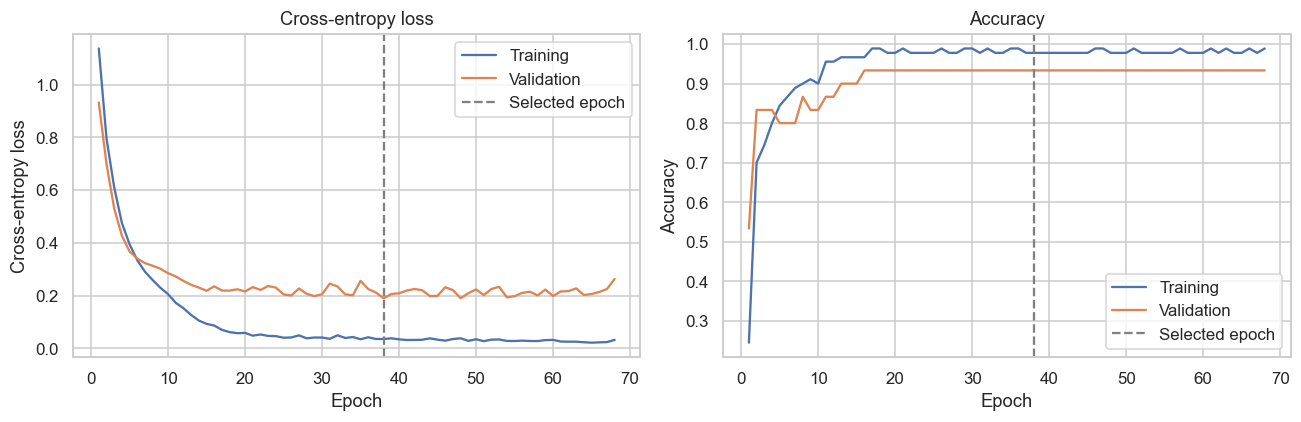

In [62]:
epoch_numbers = np.arange(1, len(history.history["loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric, title in zip(axes, ["loss", "accuracy"], ["Cross-entropy loss", "Accuracy"]):
    ax.plot(epoch_numbers, history.history[metric], label="Training")
    ax.plot(epoch_numbers, history.history["val_" + metric], label="Validation")
    ax.axvline(best_epoch, color="gray", linestyle="--", label="Selected epoch")
    ax.set(xlabel="Epoch", ylabel=title, title=title)
    ax.legend()
fig.tight_layout(); plt.show()


- Validation accuracy changes in discrete steps because only 30 flowers are used. 
- Small wiggles are expected. 
- Avoid choosing models from test-set learning curves; no test examples were used here.

### 16. Fit simple comparison models

- A most-frequent-class baseline shows what can be achieved without learning feature relationships.
- Multinomial-capable logistic regression provides a useful linear decision-boundary comparison.
- Keep scaling inside its pipeline, and train both comparisons on the same training rows as the ANN.
- Freeze these comparisons before examining the test results.


In [63]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
linear_classifier = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))])
linear_classifier.fit(X_train, y_train)
print("Baselines trained on", len(X_train), "training flowers.")

Baselines trained on 90 training flowers.


- Logistic regression is a classifier despite its name. 
- It estimates class probabilities. 
- A good ANN result is more meaningful when compared with simpler alternatives on identical data.


### 17. Evaluate the frozen models on the held-out test set

- Evaluate the ANN weights restored from the best validation-loss epoch.
- Accuracy is the proportion of correct labels; macro F1 averages per-class F1 with equal weight for each class.
- Log loss measures probability quality; lower is better. It can worsen even when accuracy improves.
- Train/validation ANN metrics below describe the restored model, rather than a mixture of historical best scores.


In [64]:
def ann_probabilities(values):
    return model(np.asarray(values, dtype="float32"), training=False).numpy()

def classification_metrics(actual, probabilities):
    predicted = np.argmax(probabilities, axis=1)
    return {"Accuracy": accuracy_score(actual, predicted),
            "Macro F1": f1_score(actual, predicted, labels=class_ids, average="macro", zero_division=0),
            "Log loss": log_loss(actual, probabilities, labels=class_ids)}

train_probabilities = ann_probabilities(X_train_scaled)
val_probabilities = ann_probabilities(X_val_scaled)
test_probabilities = ann_probabilities(X_test_scaled)
y_pred = np.argmax(test_probabilities, axis=1)
assert np.allclose(test_probabilities.sum(axis=1), 1, atol=1e-6)
ann_split_metrics = pd.DataFrame({
    "Train": classification_metrics(y_train, train_probabilities),
    "Validation": classification_metrics(y_val, val_probabilities),
    "Test": classification_metrics(y_test, test_probabilities)}).T
display(ann_split_metrics)
test_comparison = pd.DataFrame({
    "ANN": classification_metrics(y_test, test_probabilities),
    "Logistic regression": classification_metrics(y_test, linear_classifier.predict_proba(X_test)),
    "Most-frequent baseline": classification_metrics(y_test, baseline.predict_proba(X_test))}).T
display(test_comparison)
print(f"ANN: {(y_pred == y_test_array).sum()} correct out of {len(y_test_array)} test flowers.")

,Accuracy,Macro F1,Log loss
Train,0.9889,0.9889,0.0342
Validation,0.9333,0.9333,0.1894
Test,0.9333,0.9333,0.1212


,Accuracy,Macro F1,Log loss
ANN,0.9333,0.9333,0.1212
Logistic regression,0.9333,0.9333,0.2067
Most-frequent baseline,0.3333,0.1667,24.0291


ANN: 28 correct out of 30 test flowers.


- Compare the actual values, without assuming the ANN wins. 
- One small random split cannot establish model superiority. 
- Once these test diagnostics guide changes, a fresh held-out dataset is needed for another unbiased final evaluation.


### 18. Read the confusion matrix

- Rows are **true species**; columns are **predicted species**.
- Correct classifications lie on the diagonal; off-diagonal entries identify specific confusions.
- Use species names and do not transpose the matrix while retaining the original axis labels.


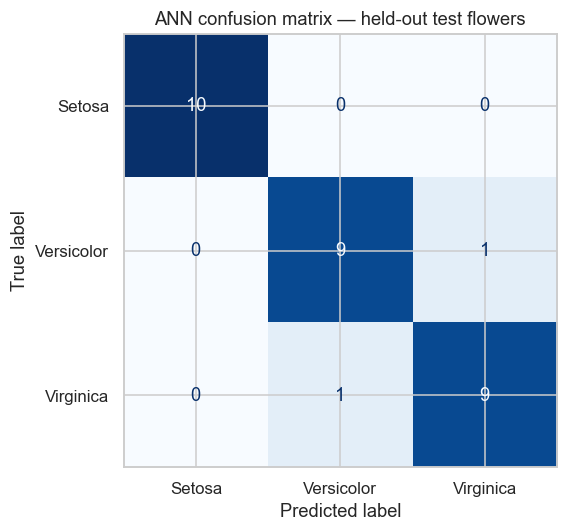

In [65]:
fig, ax = plt.subplots(figsize=(7, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=class_ids,
    display_labels=class_names, cmap="Blues", colorbar=False, ax=ax)
ax.set_title("ANN confusion matrix — held-out test flowers")
fig.tight_layout(); plt.show()

- Read an off-diagonal cell as: “flowers of the row species were predicted as the column species.” 
- Each row total is the number of test flowers belonging to that true species.

## Precision, Recall, F1-Score, and Support

For multiclass classification, we evaluate each species separately using the **one-vs-rest (OvR)** strategy. 

In each evaluation, the selected species is treated as the positive class, while the remaining two species are treated as the negative class.

### 1. True Positive (TP)
The number of flowers that actually belong to a particular species and are correctly predicted as that species.

### 2. False Positive (FP)
The number of flowers that belong to other species but are incorrectly predicted as the selected species.

### 3. False Negative (FN)
The number of flowers that actually belong to the selected species but are incorrectly predicted as another species.

### 4. True Negative (TN)
The number of flowers that belong to other species and are correctly predicted as not belonging to the selected species.

### 5. Precision

Precision measures the proportion of correctly predicted positive samples among all samples predicted as positive.

$\text{Precision} = \frac{TP}{TP+FP}$

A higher precision indicates fewer false positive predictions.

### 6. Recall (Sensitivity)

Recall measures the proportion of actual positive samples that are correctly identified by the classifier.

$\text{Recall} = \frac{TP}{TP+FN}$

A higher recall indicates fewer false negative predictions.

### 7. F1-Score

The F1-score is the harmonic mean of precision and recall. It provides a balanced measure of both metrics.

$F_1 = 2 \times \frac{\text{Precision}\times\text{Recall}}{\text{Precision}+\text{Recall}}$

Equivalently,

$F_1 = \frac{2TP}{2TP+FP+FN}$

### 8. Support

Support represents the total number of actual samples belonging to a particular class, regardless of whether they are correctly classified.

$\text{Support} = TP+FN$

### 9. Macro Average

The macro average calculates the arithmetic mean of a metric across all classes. Each class receives equal importance, regardless of its number of samples.

For $K$ classes:

$\text{Macro Average} = \frac{1}{K}\sum_{i=1}^{K} M_i$

where $M_i$ represents the metric (precision, recall, or F1-score) for class $i$.

### 10. Weighted Average

The weighted average calculates the mean of a metric across all classes, with each class weighted according to its support.

$\text{Weighted Average} =
\frac{\sum_{i=1}^{K} S_i M_i}
{\sum_{i=1}^{K} S_i}$

where:
- $K$: Number of classes.
- $S_i$: Support (number of actual samples) for class $i$.
- $M_i$: The corresponding metric for class $i$.

**Note:** If a denominator in any metric is zero, the metric is mathematically undefined. In this lesson, we use `zero_division=0` in scikit-learn to report zero in such cases and avoid undefined values in the classification report.

### 19. Inspect per-class metrics

- Report class-specific errors; a single accuracy value can hide where the model struggles.


In [66]:
report = classification_report(y_test, y_pred, labels=class_ids,
    target_names=class_names, output_dict=True, zero_division=0)
display(pd.DataFrame(report).T)

,precision,recall,f1-score,support
Setosa,1.0000,1.0000,1.0000,10.0000
Versicolor,0.9000,0.9000,0.9000,10.0000
Virginica,0.9000,0.9000,0.9000,10.0000
accuracy,0.9333,0.9333,0.9333,0.9333
macro avg,0.9333,0.9333,0.9333,30.0000
weighted avg,0.9333,0.9333,0.9333,30.0000


- Compare precision and recall for each species. 
- If every prediction is correct, discuss the tiny test sample rather than concluding that Iris classification has no uncertainty.


### 20. Review individual predictions and errors

- Keep the original row index, raw measurements, true species, predicted species, and all three probabilities together.
- Display any incorrect predictions and the least confident predictions, even if the model made no errors.
- The largest softmax probability is a model score; it is not a guarantee or a calibrated confidence measure.


In [67]:
test_results = X_test.copy()
test_results["True species"] = np.asarray(class_names)[y_test_array]
test_results["Predicted species"] = np.asarray(class_names)[y_pred]
for k, name in enumerate(class_names):
    test_results[f"P({name})"] = test_probabilities[:, k]
test_results["Largest probability"] = test_probabilities.max(axis=1)
test_results["Correct"] = y_pred == y_test_array
display(test_results.head(10))
errors = test_results.loc[~test_results["Correct"]]
print("Misclassified flowers:", len(errors))
display(errors if len(errors) else pd.DataFrame({"Message": ["No errors on this test split."]}))
display(test_results.nsmallest(5, "Largest probability"))

,Sepal_L,Sepal_W,Petal_L,Petal_W,True species,Predicted species,P(Setosa),P(Versicolor),P(Virginica),Largest probability,Correct
38,4.4,3.0,1.3,0.2,Setosa,Setosa,9.9995e-01,4.5800e-05,1.6820e-06,1.0000,True
127,6.1,3.0,4.9,1.8,Virginica,Virginica,3.3237e-05,1.5990e-02,9.8398e-01,0.9840,True
57,4.9,2.4,3.3,1.0,Versicolor,Versicolor,3.1718e-03,9.9494e-01,1.8875e-03,0.9949,True
93,5.0,2.3,3.3,1.0,Versicolor,Versicolor,6.0006e-04,9.9852e-01,8.8452e-04,0.9985,True
42,4.4,3.2,1.3,0.2,Setosa,Setosa,9.9997e-01,2.6226e-05,1.6083e-06,1.0000,True
56,6.3,3.3,4.7,1.6,Versicolor,Versicolor,5.6777e-03,7.3877e-01,2.5555e-01,0.7388,True
22,4.6,3.6,1.0,0.2,Setosa,Setosa,9.9998e-01,1.6894e-05,1.6289e-06,1.0000,True
20,5.4,3.4,1.7,0.2,Setosa,Setosa,9.9928e-01,7.0571e-04,1.7460e-05,0.9993,True
147,6.5,3.0,5.2,2.0,Virginica,Virginica,6.2113e-07,5.7125e-04,9.9943e-01,0.9994,True
84,5.4,3.0,4.5,1.5,Versicolor,Versicolor,5.2754e-03,8.5768e-01,1.3704e-01,0.8577,True


Misclassified flowers: 2


,Sepal_L,Sepal_W,Petal_L,Petal_W,True species,Predicted species,P(Setosa),P(Versicolor),P(Virginica),Largest probability,Correct
134,6.1,2.6,5.6,1.4,Virginica,Versicolor,1.6090e-05,0.6574,0.3426,0.6574,False
77,6.7,3.0,5.0,1.7,Versicolor,Virginica,5.8273e-05,0.1396,0.8604,0.8604,False


,Sepal_L,Sepal_W,Petal_L,Petal_W,True species,Predicted species,P(Setosa),P(Versicolor),P(Virginica),Largest probability,Correct
134,6.1,2.6,5.6,1.4,Virginica,Versicolor,1.6090e-05,0.6574,0.3426,0.6574,False
56,6.3,3.3,4.7,1.6,Versicolor,Versicolor,5.6777e-03,0.7388,0.2556,0.7388,True
84,5.4,3.0,4.5,1.5,Versicolor,Versicolor,5.2754e-03,0.8577,0.1370,0.8577,True
77,6.7,3.0,5.0,1.7,Versicolor,Virginica,5.8273e-05,0.1396,0.8604,0.8604,False
51,6.4,3.2,4.5,1.5,Versicolor,Versicolor,2.3480e-03,0.9563,0.0413,0.9563,True


- A confident error can be more concerning than a hesitant correct answer. 
- Probabilities should be checked for calibration on a larger independent dataset before being interpreted as reliable frequencies.

### 21. Optional: one-vs-rest ROC curves

- For each species, treat that species as positive and all others as negative.
- Vary its probability threshold to plot true positive rate (recall) against false positive rate.
- AUC measures ranking across thresholds; it does not measure calibration or replace the confusion matrix.
- This diagnostic uses only about 10 positives per species in the bundled test split, so the curves are coarse.


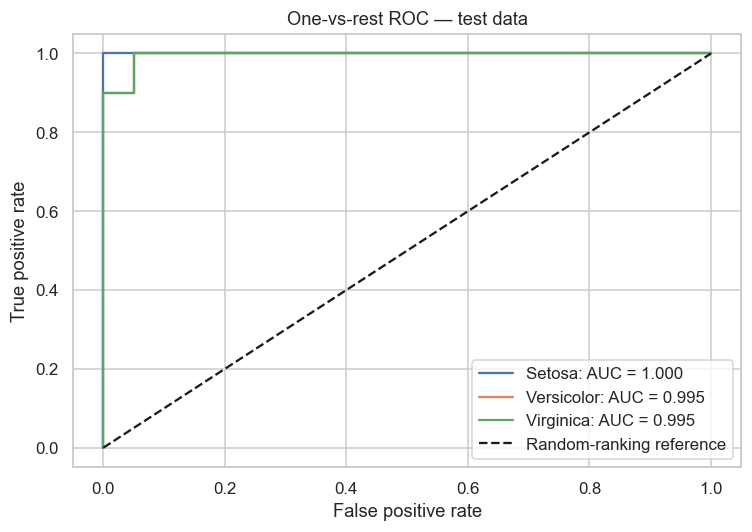

In [68]:
fig, ax = plt.subplots(figsize=(7, 5))
for k, name in enumerate(class_names):
    binary_truth = (y_test_array == k).astype(int)
    fpr, tpr, _ = roc_curve(binary_truth, test_probabilities[:, k])
    ax.plot(fpr, tpr, label=f"{name}: AUC = {auc(fpr, tpr):.3f}")
ax.plot([0, 1], [0, 1], "k--", label="Random-ranking reference")
ax.set(xlabel="False positive rate", ylabel="True positive rate",
       title="One-vs-rest ROC — test data")
ax.legend(); fig.tight_layout(); plt.show()


- A high AUC can coexist with imperfect argmax classification. 
- The final three-class prediction still chooses the largest probability; these three separate ROC threshold sweeps do not define a new multiclass prediction rule.


### 22. Predict a new flower with the fitted scaler

- Supply raw measurements in centimeters with exactly the same feature names and order.
- Apply the **training-fitted** scaler before calling the ANN. 
- Do not fit another scaler on the new flower.
- Flag values beyond individual training ranges. 
- Being within every range still does not ensure a familiar feature combination.


In [69]:
new_flowers = pd.DataFrame([{"Sepal_L": 6.4, "Sepal_W": 3.1,
                              "Petal_L": 5.5, "Petal_W": 1.8}])[feature_columns]
def predict_flowers(raw_measurements, fitted_scaler, fitted_model, names):
    if list(raw_measurements.columns) != feature_columns:
        raise ValueError(f"Use these columns in this order: {feature_columns}")
    values = raw_measurements.to_numpy(dtype=float)
    if not np.isfinite(values).all() or (values <= 0).any():
        raise ValueError("Provide finite, positive measurements in centimeters.")
    transformed = fitted_scaler.transform(raw_measurements).astype("float32")
    probabilities = fitted_model(transformed, training=False).numpy()
    result = raw_measurements.copy()
    result["Predicted species"] = np.asarray(names)[probabilities.argmax(axis=1)]
    for k, name in enumerate(names):
        result[f"P({name})"] = probabilities[:, k]
    return result

for column in feature_columns:
    if (~new_flowers[column].between(X_train[column].min(), X_train[column].max())).any():
        print(f"Caution: {column} contains a value outside its observed training range.")
new_predictions = predict_flowers(new_flowers, scaler, model, class_names)
display(new_predictions)

,Sepal_L,Sepal_W,Petal_L,Petal_W,Predicted species,P(Setosa),P(Versicolor),P(Virginica)
0,6.4,3.1,5.5,1.8,Virginica,6.4311e-06,0.0035,0.9965


- Read the three probabilities together with the predicted species. 
- A neural network can produce a high maximum probability for an unfamiliar input, so softmax alone is not a detector of out-of-distribution flowers.


### 23. Save the model, preprocessing, and label mapping

- Save the Keras model in `.keras` format, the fitted scaler with joblib, and feature order/class names in JSON.
- The network alone is insufficient for correct inference on raw measurements.
- Create the output directory first; use a filename that reflects this Iris task.
- Load joblib artifacts only from trusted sources, because deserialization can execute code.


In [70]:
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
model.save(ARTIFACT_DIR / "iris_ann.keras")
joblib.dump(scaler, ARTIFACT_DIR / "iris_scaler.joblib")
metadata = {"feature_columns": feature_columns, "class_names": class_names,
    "units": "centimeters", "random_state": RANDOM_STATE,
    "hidden_units": list(HIDDEN_UNITS), "learning_rate": LEARNING_RATE,
    "selected_epoch": best_epoch, "tensorflow_version": tf.__version__}
(ARTIFACT_DIR / "metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
print("Saved artifacts to:", ARTIFACT_DIR.resolve())


Saved artifacts to: C:\Users\user\Documents\GitHub\AI\ann_iris_artifacts


- The scaler preserves training means and standard deviations. 
- The metadata preserves the meaning and order of inputs and outputs. 
- Rerunning this cell overwrites this lesson’s artifacts in the chosen directory.


### 24. Reload and verify inference

- Reload all three artifacts and check predictions against the in-memory model.
- A numerical agreement check catches common saving/loading mistakes.
- In a new project, load the metadata first and use its feature order when building the input table.


In [71]:
reloaded_model = tf.keras.models.load_model(ARTIFACT_DIR / "iris_ann.keras", compile=False)
reloaded_scaler = joblib.load(ARTIFACT_DIR / "iris_scaler.joblib")
reloaded_metadata = json.loads((ARTIFACT_DIR / "metadata.json").read_text(encoding="utf-8"))
assert reloaded_metadata["feature_columns"] == feature_columns
reloaded_input = new_flowers[reloaded_metadata["feature_columns"]]
reloaded_probabilities = reloaded_model(
    reloaded_scaler.transform(reloaded_input).astype("float32"), training=False).numpy()
original_probabilities = ann_probabilities(scaler.transform(new_flowers).astype("float32"))
np.testing.assert_allclose(reloaded_probabilities, original_probabilities, atol=1e-6)
display(predict_flowers(reloaded_input, reloaded_scaler, reloaded_model,
                       reloaded_metadata["class_names"]))
print("Reloaded predictions match the original predictions.")


,Sepal_L,Sepal_W,Petal_L,Petal_W,Predicted species,P(Setosa),P(Versicolor),P(Virginica)
0,6.4,3.1,5.5,1.8,Virginica,6.4311e-06,0.0035,0.9965


Reloaded predictions match the original predictions.


- Successful agreement verifies that this saved model/scaler pair reproduces the example prediction.
- It does not verify generalization to new populations.
